# Week 1 · Task 2 — Trends, and the spaghetti problem

Data: `gapminder.csv` — 1,704 rows = 142 countries × 12 years (1952–2007, every 5 years); columns `country, continent, year, lifeExp, pop, gdpPercap`. No missing values.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt          # only plt.subplots() is used; every chart is drawn with methods on ax
from matplotlib.ticker import FuncFormatter
from pathlib import Path

DATA = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 1\gapminder.csv")                       # folder made by download_assignment_data.py
GREY, DARK = "#bbbbbb", "#444444"
COL = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "pink": "#CC79A7", "red": "#D55E00", "sky": "#56B4E9"}
mpl.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def note(fig, text, y=-0.03):
    # one-line footnote: sample size and any excluded rows are declared on the figure itself
    fig.text(0.01, y, text, fontsize=8, ha="left")

In [2]:
gap = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 1\gapminder.csv")
N = gap["country"].nunique()
print(gap.shape, "|", N, "countries |", gap["year"].nunique(), "years | missing values:", int(gap.isna().sum().sum()))
gap.head()

(1704, 6) | 142 countries | 12 years | missing values: 0


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


## 1. The messy chart, on purpose: 142 lines and a legend

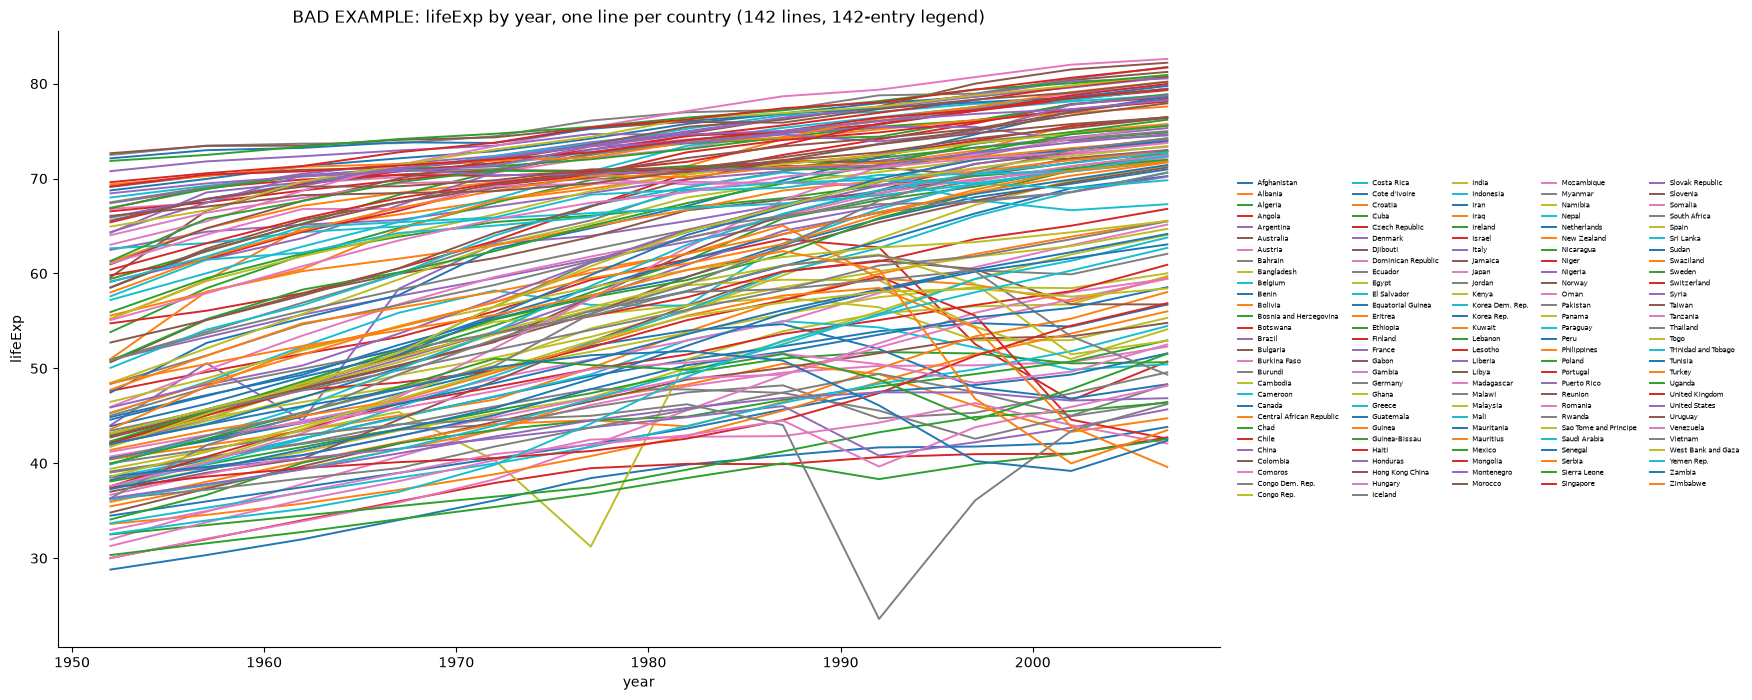

In [3]:
fig, ax = plt.subplots(figsize=(15, 8))
for country, d in gap.groupby("country"):
    ax.plot(d["year"], d["lifeExp"], lw=1.4, label=country)             # default colour cycle: 10 colours repeated 14 times
ax.legend(ncol=5, fontsize=5, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
ax.set_xlabel("year"); ax.set_ylabel("lifeExp")
ax.set_title("BAD EXAMPLE: lifeExp by year, one line per country (142 lines, 142-entry legend)")
fig.savefig("w1_task2_bad_example.png", dpi=200, bbox_inches="tight")

**Everything wrong with it**

1. **Overplotting:** 142 lines pile up in the same band (roughly 40 to 80 years), so most of the individual lines cannot be followed.
2. **Colour means nothing:** matplotlib repeats 10 colours, so each colour is shared by about 14 countries. Colour suggests a grouping that does not exist.
3. **The legend is unusable:** 142 entries in tiny type; to identify one line the reader must match a colour (shared by 14 lines) to a name. It also steals a third of the figure width.
4. **No message:** the title names the axes and no finding. A reader cannot say what the chart is *for*.
5. **Nothing is highlighted, so nothing is found:** the interesting lines (Rwanda's collapse in 1992, steep climbers like China) are buried.
6. **Wrong question for this chart:** a line per entity works for about 5 lines; at 142 the viewer sees texture, not trends.

## 2a. Fix by aggregating: one line per continent

continent,Africa,Americas,Asia,Europe,Oceania
year,,,,,
1952,38.8,60.2,42.9,64.9,69.2
2007,54.6,75.4,69.4,77.9,81.1


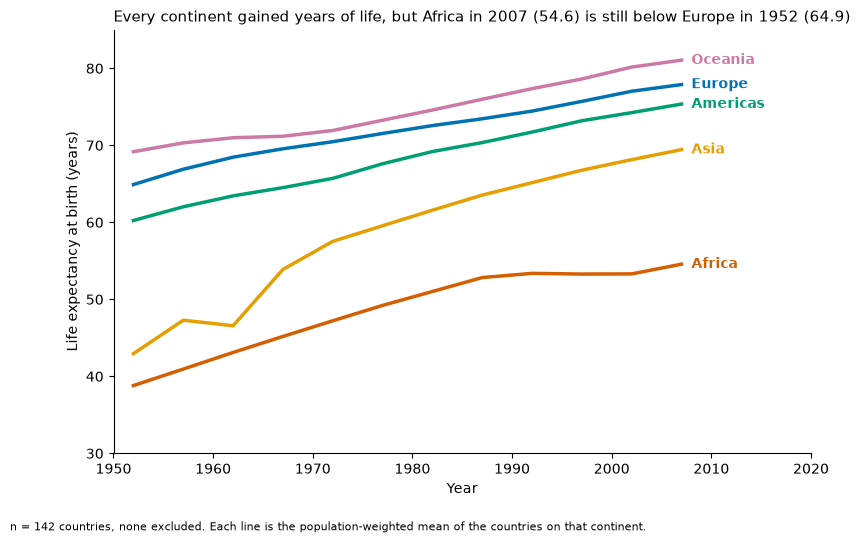

In [4]:
def wavg(d):
    return np.average(d["lifeExp"], weights=d["pop"])

cont = gap.groupby(["continent", "year"])[["lifeExp", "pop"]].apply(wavg).unstack(0)    # population-weighted mean life expectancy
display(cont.round(1).loc[[1952, 2007]])

palette = {"Africa": COL["red"], "Americas": COL["green"], "Asia": COL["orange"], "Europe": COL["blue"], "Oceania": COL["pink"]}
fig, ax = plt.subplots(figsize=(9, 5.5))
for c in cont.columns:
    ax.plot(cont.index, cont[c], color=palette[c], lw=2.5)
    ax.text(2008, cont[c].iloc[-1], c, color=palette[c], va="center", fontweight="bold")        # direct labels, no legend
ax.set_xlim(1950, 2020); ax.set_ylim(30, 85)
ax.set_xlabel("Year"); ax.set_ylabel("Life expectancy at birth (years)")
a07, e52 = cont["Africa"].iloc[-1], cont["Europe"].iloc[0]
if a07 < e52:
    title = f"Every continent gained years of life, but Africa in 2007 ({a07:.1f}) is still below Europe in 1952 ({e52:.1f})"
else:
    title = "Every continent gained years of life between 1952 and 2007"
ax.set_title(title, loc="left", fontsize=11)
note(fig, f"n = {N} countries, none excluded. Each line is the population-weighted mean of the countries on that continent.")
fig.savefig("w1_task2_continents.png", dpi=200, bbox_inches="tight")

**Why this chart type.** Time on the x-axis and a continuous measure on the y-axis is exactly what a line chart is for, and five lines are few enough to read, so colour (meaning *continent*) is justified, and direct labels replace the legend.
I weighted by population so each line describes the average *person* on that continent rather than the average country (which would let tiny countries count as much as China and India). That choice is declared on the chart.

## 2b. Fix by highlighting: keep all 142 lines, colour only three

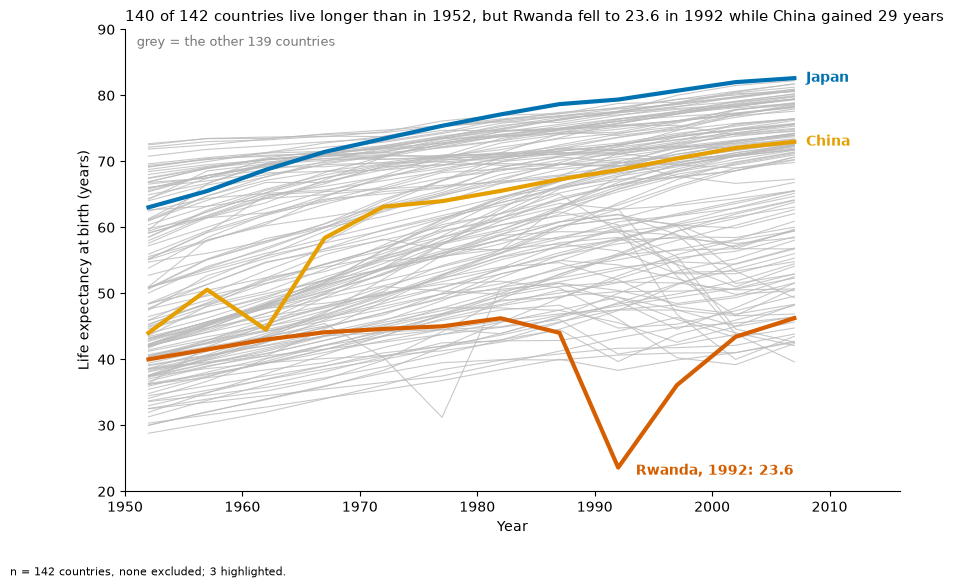

In [5]:
chosen = {"China": COL["orange"], "Rwanda": COL["red"], "Japan": COL["blue"]}
fig, ax = plt.subplots(figsize=(10, 6))
for country, d in gap.groupby("country"):
    if country not in chosen:
        ax.plot(d["year"], d["lifeExp"], color=GREY, lw=0.8, alpha=0.8, zorder=1)
for country, colr in chosen.items():
    d = gap[gap["country"] == country]
    ax.plot(d["year"], d["lifeExp"], color=colr, lw=3, zorder=3)
w = gap.pivot_table(index="country", columns="year", values="lifeExp")
rw_low = w.loc["Rwanda"].min(); rw_year = int(w.loc["Rwanda"].idxmin())
ax.text(2008, w.loc["China", 2007], "China", color=chosen["China"], fontweight="bold", va="center")
ax.text(2008, w.loc["Japan", 2007], "Japan", color=chosen["Japan"], fontweight="bold", va="center")
ax.annotate(f"Rwanda, {rw_year}: {rw_low:.1f}", xy=(rw_year, rw_low), xytext=(rw_year + 1.5, rw_low - 0.5), color=chosen["Rwanda"], fontweight="bold", va="center")
ax.text(1951, 87.5, "grey = the other 139 countries", color="#777777", fontsize=9)
ax.set_xlim(1950, 2016); ax.set_ylim(20, 90)
ax.set_xlabel("Year"); ax.set_ylabel("Life expectancy at birth (years)")
gained = int(((w[2007] - w[1952]) > 0).sum()); china_gain = w.loc["China", 2007] - w.loc["China", 1952]
ax.set_title(f"{gained} of {N} countries live longer than in 1952, but Rwanda fell to {rw_low:.1f} in {rw_year} while China gained {china_gain:.0f} years", loc="left", fontsize=11)
note(fig, f"n = {N} countries, none excluded; 3 highlighted.")
fig.savefig("w1_task2_highlight.png", dpi=200, bbox_inches="tight")

**Why this chart type.** The same line chart, but the design does the reading for the viewer: grey context keeps every country visible, and only three lines get colour, so the eye goes straight to them. Each is labelled directly on the chart (no legend). I chose China (the largest climb among big countries), Japan (the long-run leader, a reference for "high") and Rwanda (a collapse inside the data, the 1992 genocide period).

## 3. (a) versus (b): what each can show that the other cannot

| | (a) Aggregate: one line per continent | (b) Highlight: 142 grey lines + 3 coloured |
|---|---|---|
| **Shows well** | The overall trend per group, comparisons between groups, and the ordering of continents, in a form that can be read in two seconds | The *spread* inside the world: how far apart countries are, that almost all lines slope up, and that individual outliers exist |
| **Cannot show** | Variation inside a continent, outliers (Rwanda's 1992 dip is averaged away), and individual countries | A clean group-level comparison, since the grey mass has no groups, so "Africa vs Europe" is not visible |
| **Risk** | The average hides the story: a continent line can look smooth while its countries diverge | Editorial choice: the three highlighted countries are *my* selection and can mislead if they are not representative |
| **Best for** | A report headline: "who is ahead?" | Exploration or a "look at this one" story |

(a) answers *"how do groups compare?"*; (b) answers *"what do individuals look like against the crowd?"* — and neither alone is the whole picture.

## 4. Has the gap between the richest and poorest countries narrowed since 1952?

**Watch-out first:** `gdpPercap` is extremely skewed. A histogram shows why, and what a log scale does.

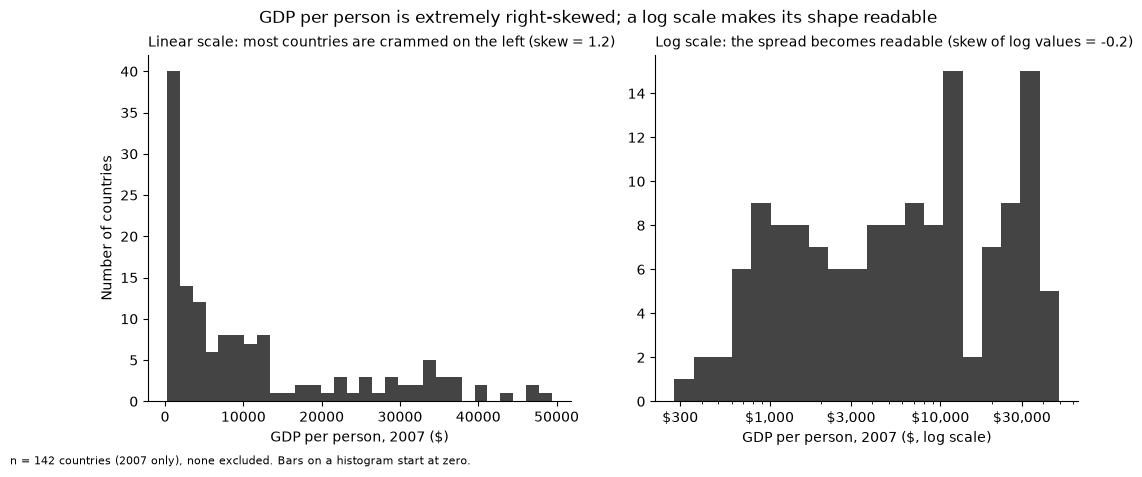

In [6]:
g07 = gap[gap["year"] == 2007]["gdpPercap"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(g07, bins=30, color=DARK)
axes[0].set_xlabel("GDP per person, 2007 ($)"); axes[0].set_ylabel("Number of countries")
axes[0].set_title(f"Linear scale: most countries are crammed on the left (skew = {g07.skew():.1f})", loc="left", fontsize=10)
axes[1].hist(g07, bins=np.logspace(np.log10(g07.min()), np.log10(g07.max()), 21), color=DARK)
axes[1].set_xscale("log")
axes[1].set_xticks([300, 1000, 3000, 10000, 30000]); axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[1].set_xlabel("GDP per person, 2007 ($, log scale)")
axes[1].set_title(f"Log scale: the spread becomes readable (skew of log values = {np.log10(g07).skew():.1f})", loc="left", fontsize=10)
fig.suptitle("GDP per person is extremely right-skewed; a log scale makes its shape readable", fontsize=12)
note(fig, f"n = {len(g07)} countries (2007 only), none excluded. Bars on a histogram start at zero.")
fig.savefig("w1_task2_gdp_hist.png", dpi=200, bbox_inches="tight")

On the linear scale a few very rich countries stretch the axis and 100+ countries sit in the first two or three bars, so it is impossible to compare them. On a log scale equal distances mean equal *ratios* (a doubling is always the same distance), which is the right way to compare "how many times richer", so I will use a log scale for the gap question. A log axis cannot show zero, so I will **not** use bars on it; lines and points only.

**Defining the gap.** "Richest vs poorest" with just the single richest and poorest countries is fragile (one outlier decides it), so I use the 10th, 50th and 90th percentile country in each year and compare their ratio.

,p10,p50,p90,ratio
year,,,,
1952,495.0,1969.0,7255.0,15.0
1977,741.0,3799.0,19092.0,26.0
2007,887.0,6124.0,33644.0,38.0


,richest,richest_gdp,poorest,poorest_gdp,richest/poorest
year,,,,,
1952,Kuwait,108382.0,Lesotho,299.0,363.0
1977,Kuwait,59265.0,Myanmar,371.0,160.0
2007,Norway,49357.0,Congo Dem. Rep.,278.0,178.0


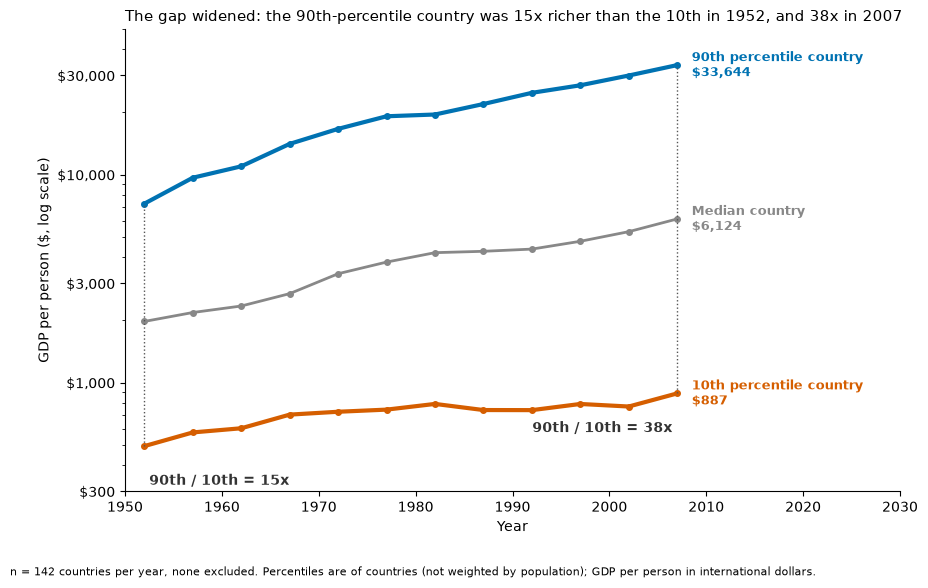

In [7]:
q = gap.groupby("year")["gdpPercap"].quantile([0.1, 0.5, 0.9]).unstack()
q.columns = ["p10", "p50", "p90"]
q["ratio"] = q["p90"] / q["p10"]
ext = gap.loc[gap.groupby("year")["gdpPercap"].idxmax()].set_index("year")[["country", "gdpPercap"]].rename(columns={"country": "richest", "gdpPercap": "richest_gdp"})
ext["poorest"] = gap.loc[gap.groupby("year")["gdpPercap"].idxmin()].set_index("year")["country"]
ext["poorest_gdp"] = gap.groupby("year")["gdpPercap"].min()
ext["richest/poorest"] = ext["richest_gdp"] / ext["poorest_gdp"]
display(q.round(0).loc[[1952, 1977, 2007]]); display(ext.round(0).loc[[1952, 1977, 2007]])

r52, r07 = q.loc[1952, "ratio"], q.loc[2007, "ratio"]
fig, ax = plt.subplots(figsize=(10, 6))
lines = {"p90": ("90th percentile country", COL["blue"]), "p50": ("Median country", "#888888"), "p10": ("10th percentile country", COL["red"])}
for k, (label, colr) in lines.items():
    ax.plot(q.index, q[k], color=colr, lw=3 if k != "p50" else 2, marker="o", ms=4)
    ax.text(2008.5, q[k].iloc[-1], f"{label}\n${q[k].iloc[-1]:,.0f}", color=colr, va="center", fontsize=9, fontweight="bold")
for yr, ha in [(1952, "left"), (2007, "right")]:
    ax.plot([yr, yr], [q.loc[yr, "p10"], q.loc[yr, "p90"]], color="#555555", lw=1, ls=":")
    ax.text(yr + (0.5 if ha == "left" else -0.5), q.loc[yr, "p10"] * 0.68, f"90th / 10th = {q.loc[yr, 'ratio']:.0f}x", ha=ha, va="center", fontweight="bold", color="#333333")
ax.set_yscale("log"); ax.set_yticks([300, 1000, 3000, 10000, 30000]); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlim(1950, 2030); ax.set_ylim(300, 50000)
ax.set_xlabel("Year"); ax.set_ylabel("GDP per person ($, log scale)")
ax.set_title(f"The gap widened: the 90th-percentile country was {r52:.0f}x richer than the 10th in 1952, and {r07:.0f}x in 2007", loc="left", fontsize=11)
note(fig, f"n = {N} countries per year, none excluded. Percentiles are of countries (not weighted by population); GDP per person in international dollars.")
fig.savefig("w1_task2_gap.png", dpi=200, bbox_inches="tight")

**Why this chart.** A line chart of three percentiles over time on a log axis. Lines are right for a time trend; percentiles are robust to a single extreme country; the log scale means *parallel lines would mean a constant ratio*, so the lines fanning apart is visible evidence that the ratio is growing. The brackets and "15x / 38x" labels give the ratio directly. One axis only; no legend, direct labels; no bars on a log axis.

**Answer.** By this measure the gap has **not narrowed, it has widened**: the 90th/10th percentile ratio rose from about 15 to about 38. Rich countries pulled away from poor ones in relative terms, and in absolute dollars the gap grew far more.
There is a catch worth stating: the ratio of the single richest to the single poorest country *did* fall (compare the table above) because Kuwait, the richest country in 1952, fell sharply later and the poorest country's income stayed very low. That extreme-to-extreme number is decided by two countries, so it says little about the world as a whole, which is why I did not use it as the headline.